```markdown
# Client Churn Prediction & Value-at-Risk Analysis
This notebook demonstrates an end-to-end data science workflow to analyze customer behavior, build predictive models for customer churn, identify high-risk accounts, and estimate the financial brokerage impact of potential churn.

### Notebook Structure
1. **Data Loading & Inspection**
2. **Exploratory Data Analysis (EDA)**
3. **Data Cleaning & Standardization**
4. **Feature Engineering**
5. **Validation Strategy & Backtesting**
6. **Model Selection & Evaluation (Baseline vs. Logistic Regression vs. Random Forest)**
7. **Feature Importance**
8. **Actionable Recommendations & Calling List Generation**
9. **Brokerage Impact & Churn Evaluation**
```

In [1]:
import pandas as pd
import numpy as np

```markdown
## 1. Data Loading & Inspection
Let's load the clients and transaction orders datasets to understand the starting shape and properties of our source data.
```

In [ ]:
clients = pd.read_csv("C:\\Users\\admin\\Downloads\\Sonali_Goyal_Tradegini_Assignment\\clients.csv")
orders = pd.read_csv("C:\\Users\\admin\\Downloads\\Sonali_Goyal_Tradegini_Assignment\\orders.csv")

In [3]:
print("Clients shape:", clients.shape)
print("Orders shape:", orders.shape)

Clients shape: (4000, 8)
Orders shape: (50732, 10)


In [4]:
display(clients.head())
display(orders.head())

,client_id,onboarding_date,city_tier,age_band,acquisition_channel,fno_enabled,api_enabled,last_login_date
0,TJ100000,2026-06-17,Tier 1,26-35,paid_ads,True,False,2026-06-25
1,TJ100001,2025-06-21,Tier 3,26-35,organic,False,False,2026-05-08
2,TJ100002,2026-07-07,Tier 3,60+,paid_ads,True,False,2026-08-22
3,TJ100003,2026-04-05,Tier 2,18-25,organic,True,False,2026-09-30
4,TJ100004,2025-08-05,Tier 1,26-35,organic,False,False,2026-05-26


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
0,ORD26002348,TJ103190,2026-01-06 10:06:12,OPT,mobile,BUY,7335.00,EXECUTED,NaN,3.67
1,ORD26109998,TJ100771,2026-06-26 11:31:15,Opt,mobile,BUY,44967.91,EXECUTED,NaN,20.00
2,ORD26081437,TJ102642,2026-05-19 13:19:00,OPT,api,BUY,6606.22,EXECUTED,NaN,3.30
3,ORD26178769,TJ103021,2026-09-23 15:17:36,OPT,api,BUY,124828.43,EXECUTED,NaN,20.00
4,ORD26019357,TJ103991,2026-02-06 12:53:09,FUT,mobile,BUY,692252.54,EXECUTED,NaN,20.00


In [5]:
print("Client columns:")
print(clients.columns.tolist())

print("\nOrder columns:")
print(orders.columns.tolist())

Client columns:
['client_id', 'onboarding_date', 'city_tier', 'age_band', 'acquisition_channel', 'fno_enabled', 'api_enabled', 'last_login_date']

Order columns:
['order_id', 'client_id', 'order_ts', 'segment', 'platform', 'side', 'turnover_inr', 'status', 'reject_reason', 'brokerage_inr']


In [6]:
print("Clients information:")
clients.info()

print("\nOrders information:")
orders.info()

Clients information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   client_id            4000 non-null   object
 1   onboarding_date      4000 non-null   object
 2   city_tier            4000 non-null   object
 3   age_band             3910 non-null   object
 4   acquisition_channel  4000 non-null   object
 5   fno_enabled          4000 non-null   bool  
 6   api_enabled          4000 non-null   bool  
 7   last_login_date      4000 non-null   object
dtypes: bool(2), object(6)
memory usage: 195.4+ KB

Orders information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50732 entries, 0 to 50731
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       50732 non-null  object 
 1   client_id      50732 non-null  object 
 2   order_ts       50732 

```markdown
## 2. Exploratory Data Analysis & Quality Checks
We will inspect missing values, duplicates, unexpected distributions, and potential anomalies in dates, turnover, and brokerage values.
```

In [7]:
print("Missing values in clients:")
display(clients.isnull().sum())

print("Missing values in orders:")
display(orders.isnull().sum())

Missing values in clients:


,0
client_id,0
onboarding_date,0
city_tier,0
age_band,90
acquisition_channel,0
fno_enabled,0
api_enabled,0
last_login_date,0


Missing values in orders:


,0
order_id,0
client_id,0
order_ts,0
segment,0
platform,757
side,0
turnover_inr,0
status,0
reject_reason,47132
brokerage_inr,1


In [8]:
print("Duplicate client rows:", clients.duplicated().sum())
print("Duplicate order rows:", orders.duplicated().sum())

Duplicate client rows: 0
Duplicate order rows: 38


In [9]:
print("Missing values:")
print(pd.concat([
    clients.isnull().sum().rename("Clients"),
    orders.isnull().sum().rename("Orders")
], axis=1).fillna(0))

print("\nDuplicate client IDs:", clients["client_id"].duplicated().sum())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Duplicate order rows:", orders.duplicated().sum())

Missing values:
                     Clients   Orders
client_id                0.0      0.0
onboarding_date          0.0      0.0
city_tier                0.0      0.0
age_band                90.0      0.0
acquisition_channel      0.0      0.0
fno_enabled              0.0      0.0
api_enabled              0.0      0.0
last_login_date          0.0      0.0
order_id                 0.0      0.0
order_ts                 0.0      0.0
segment                  0.0      0.0
platform                 0.0    757.0
side                     0.0      0.0
turnover_inr             0.0      0.0
status                   0.0      0.0
reject_reason            0.0  47132.0
brokerage_inr            0.0      1.0

Duplicate client IDs: 0
Duplicate order IDs: 38
Duplicate order rows: 38


In [10]:
for col in ["city_tier", "age_band", "acquisition_channel"]:
    print("\n", col)
    print(clients[col].value_counts(dropna=False))

for col in ["segment", "platform", "side", "status", "reject_reason"]:
    print("\n", col)
    print(orders[col].value_counts(dropna=False))


 city_tier
city_tier
Tier 1    1791
Tier 2    1409
Tier 3     800
Name: count, dtype: int64

 age_band
age_band
26-35    1520
36-45     864
18-25     817
46-60     523
60+       186
NaN        90
Name: count, dtype: int64

 acquisition_channel
acquisition_channel
organic         1624
paid_ads        1115
referral         868
algo_partner     393
Name: count, dtype: int64

 segment
segment
OPT             24055
EQ_INTRADAY     10267
EQ_DELIVERY      9395
FUT              5975
OPT               176
opt               171
Opt               165
Eq_Delivery        73
eq_delivery        71
Eq_Intraday        67
eq_intraday        66
EQ_INTRADAY        65
EQ_DELIVERY        61
FUT                53
fut                41
Fut                31
Name: count, dtype: int64

 platform
platform
mobile    21580
api       21195
web        7200
NaN         757
Name: count, dtype: int64

 side
side
BUY     26743
SELL    23989
Name: count, dtype: int64

 status
status
EXECUTED     43640
REJECTED      3600

In [11]:
orders["order_ts"] = pd.to_datetime(orders["order_ts"])
clients["onboarding_date"] = pd.to_datetime(clients["onboarding_date"])
clients["last_login_date"] = pd.to_datetime(clients["last_login_date"])

print("Order date range:", orders["order_ts"].min(), orders["order_ts"].max())

print("Weekend orders:",
      (orders["order_ts"].dt.dayofweek >= 5).sum())

print("Orders on holidays:",
      orders["order_ts"].dt.strftime("%m-%d").isin(["01-26", "05-01"]).sum())

print("Invalid market hours:",
      ((orders["order_ts"].dt.time < pd.Timestamp("09:15").time()) |
       (orders["order_ts"].dt.time > pd.Timestamp("15:30").time())).sum())

Order date range: 2026-01-01 09:15:15 2026-10-03 13:09:56
Weekend orders: 122
Orders on holidays: 0
Invalid market hours: 0


In [12]:
print("Negative turnover:", (orders["turnover_inr"] < 0).sum())

print("Negative brokerage:", (orders["brokerage_inr"] < 0).sum())

expected = np.minimum(20, orders["turnover_inr"] * 0.0005)

wrong_brokerage = (
    orders["status"].eq("EXECUTED") &
    ~np.isclose(orders["brokerage_inr"], expected, atol=0.01)
)

print("Incorrect executed brokerage:", wrong_brokerage.sum())

print("Non-executed orders with brokerage:",
      ((orders["status"] != "EXECUTED") &
       (orders["brokerage_inr"] > 0)).sum())

Negative turnover: 42
Negative brokerage: 0
Incorrect executed brokerage: 34
Non-executed orders with brokerage: 63


In [13]:
unknown = orders[~orders["client_id"].isin(clients["client_id"])]

print("Orders with unknown client IDs:", len(unknown))
print("Unique unknown clients:", unknown["client_id"].nunique())

Orders with unknown client IDs: 13
Unique unknown clients: 7


```markdown
### Analyzing Outliers, Anomalies & Segments
Let's dive deeper into suspicious rows (such as unknown client IDs, negative turnover, incorrect brokerage charges, and weekend orders).
```

In [14]:
print(pd.crosstab(orders["status"], orders["platform"], dropna=False))

platform     api  mobile   web  NaN
status                             
CANCELLED   1435    1525   478   53
EXEC           1       0     0    0
EXECUTED   18253   18504  6237  646
REJECTED    1506    1551   485   58


In [15]:
oct_orders = orders[orders["order_ts"] > "2026-09-30 23:59:59"]

print("October orders:", len(oct_orders))
display(oct_orders.head(10))

October orders: 1


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
36979,ORD26181638,TJ101528,2026-10-03 13:09:56,OPT,mobile,SELL,20960.7,EXECUTED,NaN,10.48


In [16]:
weekend_orders = orders[orders["order_ts"].dt.dayofweek >= 5]

print("Weekend orders:", len(weekend_orders))
display(weekend_orders.head(10))

Weekend orders: 122


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
812,ORD26004109,TJ103094,2026-01-11 13:03:07,OPT,mobile,SELL,40051.63,EXECUTED,NaN,20.00
1054,ORD26077286,TJ102099,2026-05-16 12:07:03,FUT,web,BUY,271416.98,EXECUTED,NaN,20.00
1196,ORD26048826,TJ103491,2026-03-29 13:12:36,EQ_INTRADAY,mobile,BUY,7089.13,REJECTED,PRICE_BAND,0.00
1262,ORD26110738,TJ103970,2026-07-04 09:32:46,EQ_INTRADAY,mobile,SELL,9710.05,EXECUTED,NaN,4.86
2113,ORD26136290,TJ102339,2026-08-02 14:38:18,OPT,web,BUY,16742.37,EXECUTED,NaN,8.37
3065,ORD26066809,TJ101912,2026-05-02 11:37:10,EQ_INTRADAY,mobile,SELL,16722.55,REJECTED,RMS_RULE,0.00
3260,ORD26132982,TJ102937,2026-08-01 14:40:19,OPT,web,BUY,99443.96,EXECUTED,NaN,20.00
3789,ORD26114965,TJ101017,2026-07-05 09:43:56,EQ_DELIVERY,mobile,SELL,9580.28,CANCELLED,NaN,0.00
4172,ORD26065620,TJ101537,2026-04-26 15:24:54,OPT,api,BUY,7055.88,EXECUTED,NaN,3.53
4762,ORD26114852,TJ102703,2026-07-05 15:18:45,EQ_DELIVERY,web,BUY,142227.54,EXECUTED,NaN,20.00


In [17]:
negative_orders = orders[orders["turnover_inr"] < 0]

print("Negative turnover:", len(negative_orders))
display(negative_orders.head(10))

Negative turnover: 42


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
1855,ORD26085445,TJ101807,2026-05-25 13:40:34,EQ_DELIVERY,api,BUY,-27979.09,EXECUTED,NaN,13.99
2361,ORD26036691,TJ103594,2026-03-10 09:33:18,EQ_DELIVERY,mobile,SELL,-9075.12,CANCELLED,NaN,0.00
4339,ORD26072137,TJ103630,2026-05-06 10:10:53,OPT,api,SELL,-23910.21,CANCELLED,NaN,0.00
5063,ORD26034429,TJ102660,2026-03-05 12:18:29,OPT,mobile,BUY,-7426.84,EXECUTED,NaN,3.71
5187,ORD26167503,TJ102910,2026-09-09 11:49:16,EQ_INTRADAY,mobile,BUY,-22954.66,EXECUTED,NaN,11.48
5616,ORD26103141,TJ103539,2026-06-17 14:15:10,EQ_INTRADAY,api,BUY,-54321.22,EXECUTED,NaN,20.00
5650,ORD26006048,TJ101807,2026-01-13 10:21:07,OPT,api,SELL,-35558.16,EXECUTED,NaN,17.78
6985,ORD26095217,TJ101807,2026-06-08 10:54:26,OPT,api,SELL,-6199.08,EXECUTED,NaN,3.10
7492,ORD26135509,TJ100291,2026-07-30 10:18:10,EQ_DELIVERY,mobile,BUY,-23051.52,EXECUTED,NaN,11.53
7639,ORD26104791,TJ101681,2026-06-19 11:33:11,OPT,api,SELL,-47656.25,REJECTED,MARGIN_SHORTFALL,0.00


In [18]:
expected = np.minimum(20, orders["turnover_inr"] * 0.0005)

wrong = orders[
    (orders["status"] == "EXECUTED") &
    (~np.isclose(orders["brokerage_inr"], expected, atol=0.01))
]

print("Incorrect brokerage:", len(wrong))
display(wrong.head(10))

Incorrect brokerage: 34


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
1855,ORD26085445,TJ101807,2026-05-25 13:40:34,EQ_DELIVERY,api,BUY,-27979.09,EXECUTED,NaN,13.99
5063,ORD26034429,TJ102660,2026-03-05 12:18:29,OPT,mobile,BUY,-7426.84,EXECUTED,NaN,3.71
5187,ORD26167503,TJ102910,2026-09-09 11:49:16,EQ_INTRADAY,mobile,BUY,-22954.66,EXECUTED,NaN,11.48
5616,ORD26103141,TJ103539,2026-06-17 14:15:10,EQ_INTRADAY,api,BUY,-54321.22,EXECUTED,NaN,20.00
5650,ORD26006048,TJ101807,2026-01-13 10:21:07,OPT,api,SELL,-35558.16,EXECUTED,NaN,17.78
6985,ORD26095217,TJ101807,2026-06-08 10:54:26,OPT,api,SELL,-6199.08,EXECUTED,NaN,3.10
7492,ORD26135509,TJ100291,2026-07-30 10:18:10,EQ_DELIVERY,mobile,BUY,-23051.52,EXECUTED,NaN,11.53
10158,ORD26037486,TJ101568,2026-03-10 14:54:09,EQ_INTRADAY,mobile,SELL,-80112.94,EXECUTED,NaN,20.00
11561,ORD26065644,TJ100658,2026-04-24 09:19:11,EQ_INTRADAY,mobile,BUY,-51451.55,EXECUTED,NaN,20.00
11955,ORD26049233,TJ101095,2026-03-30 09:49:52,OPT,api,SELL,-30225.68,EXECUTED,NaN,15.11


In [19]:
non_executed = orders[
    (orders["status"] != "EXECUTED") &
    (orders["brokerage_inr"] > 0)
]

print("Non-executed orders with brokerage:", len(non_executed))
display(non_executed.head(10))

Non-executed orders with brokerage: 63


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
1544,ORD26155501,TJ102285,2026-08-25 11:15:16,OPT,mobile,SELL,130814.92,REJECTED,MARGIN_SHORTFALL,20.0
1734,ORD26076895,TJ103494,2026-05-13 09:32:59,EQ_DELIVERY,mobile,SELL,54662.07,REJECTED,RMS_RULE,20.0
2302,ORD26154045,TJ103539,2026-08-24 09:23:12,FUT,api,SELL,616387.37,REJECTED,MARGIN_SHORTFALL,20.0
2751,ORD26049413,TJ100276,2026-03-30 10:59:16,OPT,api,SELL,13101.59,REJECTED,RMS_RULE,20.0
3997,ORD26036531,TJ100501,2026-03-09 14:37:09,EQ_INTRADAY,web,BUY,34710.72,REJECTED,PRICE_BAND,20.0
4028,ORD26158229,TJ103539,2026-08-27 13:57:43,FUT,api,SELL,576862.55,REJECTED,MARGIN_SHORTFALL,20.0
4178,ORD26106775,TJ103764,2026-06-23 11:09:37,OPT,api,SELL,14365.84,REJECTED,RMS_RULE,20.0
4382,ORD26143619,TJ103151,2026-08-10 13:02:34,EQ_INTRADAY,mobile,SELL,9314.20,REJECTED,MARGIN_SHORTFALL,20.0
4567,ORD26103706,TJ103941,2026-06-18 11:23:46,OPT,web,BUY,6359.94,REJECTED,PRICE_BAND,20.0
4775,ORD26018357,TJ102586,2026-02-05 11:02:39,OPT,mobile,SELL,24777.01,REJECTED,MARGIN_SHORTFALL,20.0


In [20]:
unknown = orders[
    ~orders["client_id"].isin(clients["client_id"])
]

print("Unknown client orders:", len(unknown))
display(unknown.head(10))

Unknown client orders: 13


,order_id,client_id,order_ts,segment,platform,side,turnover_inr,status,reject_reason,brokerage_inr
2411,ORD26018463,TJ900008,2026-02-05 12:04:45,FUT,api,SELL,7572750.44,CANCELLED,NaN,0.00
4651,ORD26109913,TJ900003,2026-06-26 11:02:47,EQ_DELIVERY,web,SELL,60421.91,EXECUTED,NaN,20.00
8383,ORD26106167,TJ900006,2026-06-22 13:40:21,EQ_INTRADAY,web,BUY,7687.88,EXECUTED,NaN,3.84
9588,ORD26100560,TJ900006,2026-06-15 11:19:14,OPT,api,SELL,8327.37,EXECUTED,NaN,4.16
16748,ORD26161886,TJ900007,2026-09-02 10:15:11,FUT,api,BUY,377954.15,EXECUTED,NaN,20.00
22677,ORD26124968,TJ900003,2026-07-16 12:02:07,OPT,mobile,BUY,212411.22,EXECUTED,NaN,20.00
29768,ORD26075800,TJ900010,2026-05-11 14:54:59,EQ_INTRADAY,mobile,SELL,34060.19,EXECUTED,NaN,17.03
37844,ORD26131873,TJ900006,2026-07-24 14:48:36,EQ_INTRADAY,web,BUY,14883.90,EXECUTED,NaN,7.44
38130,ORD26023216,TJ900005,2026-02-13 12:00:59,OPT,api,BUY,26122.36,EXECUTED,NaN,13.06
40302,ORD26081979,TJ900007,2026-05-20 10:19:28,EQ_INTRADAY,api,BUY,15439.64,EXECUTED,NaN,7.72


In [21]:
print("Original segment values:")
print(orders["segment"].value_counts())

print("\nAfter standardizing capitalization:")
print(orders["segment"].str.strip().str.upper().value_counts())

Original segment values:
segment
OPT             24055
EQ_INTRADAY     10267
EQ_DELIVERY      9395
FUT              5975
OPT               176
opt               171
Opt               165
Eq_Delivery        73
eq_delivery        71
Eq_Intraday        67
eq_intraday        66
EQ_INTRADAY        65
EQ_DELIVERY        61
FUT                53
fut                41
Fut                31
Name: count, dtype: int64

After standardizing capitalization:
segment
OPT            24567
EQ_INTRADAY    10465
EQ_DELIVERY     9600
FUT             6100
Name: count, dtype: int64


```markdown
## 3. Data Cleaning and Preprocessing Pipeline
Now, we implement a comprehensive data-cleaning workflow to address capitalization issues, filter out weekends and post-September dates, handle missing records, and recalculate expected executed brokerage fees.
```

In [22]:
# Create copies
clients_clean = clients.copy()
orders_clean = orders.copy()

# Remove exact duplicate orders
orders_clean = orders_clean.drop_duplicates()

# Fill missing values
clients_clean["age_band"] = clients_clean["age_band"].fillna("Unknown")
orders_clean["platform"] = orders_clean["platform"].fillna("Unknown")

# Standardize text categories
for col in ["segment", "platform", "side", "status"]:
    orders_clean[col] = orders_clean[col].str.strip().str.upper()

for col in ["city_tier", "age_band", "acquisition_channel"]:
    clients_clean[col] = clients_clean[col].str.strip().str.upper()

# Remove orders after September 30
orders_clean = orders_clean[
    orders_clean["order_ts"] <= "2026-09-30 23:59:59"
]

# Remove weekend orders
orders_clean = orders_clean[
    orders_clean["order_ts"].dt.dayofweek < 5
]

# Remove orders with unknown client IDs
orders_clean = orders_clean[
    orders_clean["client_id"].isin(clients_clean["client_id"])
]

# Flag negative turnover
orders_clean["invalid_turnover"] = (
    orders_clean["turnover_inr"] < 0
)

# Calculate validated brokerage
expected = np.minimum(
    20,
    orders_clean["turnover_inr"] * 0.0005
)

orders_clean["validated_brokerage"] = np.where(
    orders_clean["status"] == "EXECUTED",
    np.where(orders_clean["turnover_inr"] >= 0, expected, np.nan),
    0
)

print("Cleaning completed!")

Cleaning completed!


In [23]:
print("Original clients:", clients.shape)
print("Clean clients:", clients_clean.shape)

print("Original orders:", orders.shape)
print("Clean orders:", orders_clean.shape)

print("\nRemaining duplicate orders:",
      orders_clean.duplicated().sum())

print("\nMissing values:")
print(orders_clean.isnull().sum())

print("\nSegments:")
print(orders_clean["segment"].value_counts())

Original clients: (4000, 8)
Clean clients: (4000, 8)
Original orders: (50732, 10)
Clean orders: (50559, 12)

Remaining duplicate orders: 0

Missing values:
order_id                   0
client_id                  0
order_ts                   0
segment                    0
platform                   0
side                       0
turnover_inr               0
status                     0
reject_reason          46974
brokerage_inr              1
invalid_turnover           0
validated_brokerage       34
dtype: int64

Segments:
segment
OPT            24488
EQ_INTRADAY    10427
EQ_DELIVERY     9568
FUT             6076
Name: count, dtype: int64


In [24]:
clients_clean.to_csv("clients_clean.csv", index=False)
orders_clean.to_csv("orders_clean.csv", index=False)

print("Cleaned files saved successfully!")

Cleaned files saved successfully!


```markdown
## 4. Historical Business Performance Overview
With clean datasets ready, let's examine overall business health metrics, monthly trend statistics, and distributions across trading segments and platform types.
```

In [25]:
print("Total clients:", clients_clean["client_id"].nunique())

print("Total orders:", len(orders_clean))

print("Executed orders:",
      (orders_clean["status"] == "EXECUTED").sum())

print("Rejected orders:",
      (orders_clean["status"] == "REJECTED").sum())

print("Cancelled orders:",
      (orders_clean["status"] == "CANCELLED").sum())

Total clients: 4000
Total orders: 50559
Executed orders: 43493
Rejected orders: 3585
Cancelled orders: 3480


In [26]:
orders_clean["month"] = orders_clean["order_ts"].dt.month

monthly_orders = orders_clean[
    orders_clean["status"] == "EXECUTED"
].groupby("month").agg(
    total_orders=("order_id", "count"),
    active_clients=("client_id", "nunique"),
    total_turnover=("turnover_inr", "sum")
)

print(monthly_orders)

       total_orders  active_clients  total_turnover
month                                              
1              3773            1041    4.506990e+08
2              3615            1039    4.511208e+08
3              4570            1097    6.665438e+08
4              4567            1160    5.446806e+08
5              4598            1111    5.933937e+08
6              5405            1199    7.152558e+08
7              5904            1310    7.305730e+08
8              5458            1249    7.111835e+08
9              5603            1196    7.194059e+08


In [27]:
segment_analysis = orders_clean[
    orders_clean["status"] == "EXECUTED"
].groupby("segment").agg(
    total_orders=("order_id", "count"),
    total_turnover=("turnover_inr", "sum"),
    active_clients=("client_id", "nunique")
).sort_values("total_orders", ascending=False)

print(segment_analysis)

             total_orders  total_turnover  active_clients
segment                                                  
OPT                 20980    4.702314e+08            1540
EQ_INTRADAY          9006    4.005213e+08            1936
EQ_DELIVERY          8247    3.696188e+08            1859
FUT                  5260    4.342485e+09             987


In [28]:
platform_analysis = orders_clean[
    orders_clean["status"] == "EXECUTED"
].groupby("platform").agg(
    total_orders=("order_id", "count"),
    active_clients=("client_id", "nunique")
)

print(platform_analysis)

          total_orders  active_clients
platform                              
API              18191             262
MOBILE           18438            2680
UNKNOWN            646             389
WEB               6218            1156


In [29]:
channel_analysis = clients_clean.groupby(
    "acquisition_channel"
).agg(
    total_clients=("client_id", "nunique")
)

print(channel_analysis)

                     total_clients
acquisition_channel               
ALGO_PARTNER                   393
ORGANIC                       1624
PAID_ADS                      1115
REFERRAL                       868


In [30]:
client_activity = orders_clean[
    orders_clean["status"] == "EXECUTED"
].groupby("client_id").agg(
    total_orders=("order_id", "count"),
    total_turnover=("turnover_inr", "sum"),
    total_brokerage=("validated_brokerage", "sum"),
    last_trade=("order_ts", "max")
)

print(client_activity.describe())

       total_orders  total_turnover  total_brokerage  \
count   2941.000000    2.941000e+03      2941.000000   
mean      14.788507    1.898285e+06       181.592730   
min        1.000000   -2.305152e+04         0.000000   
25%        2.000000    5.920860e+04        20.000000   
50%        4.000000    2.242850e+05        52.720790   
75%       11.000000    1.052310e+06       144.888490   
max     2484.000000    3.521476e+08     29597.783680   
std       68.249887    1.008177e+07       815.966791   

                          last_trade  
count                           2941  
mean   2026-07-09 15:37:26.660659712  
min              2026-01-01 09:39:53  
25%              2026-05-08 09:32:42  
50%              2026-08-12 11:06:43  
75%              2026-09-18 12:41:07  
max              2026-09-30 15:29:12  
std                              NaN  


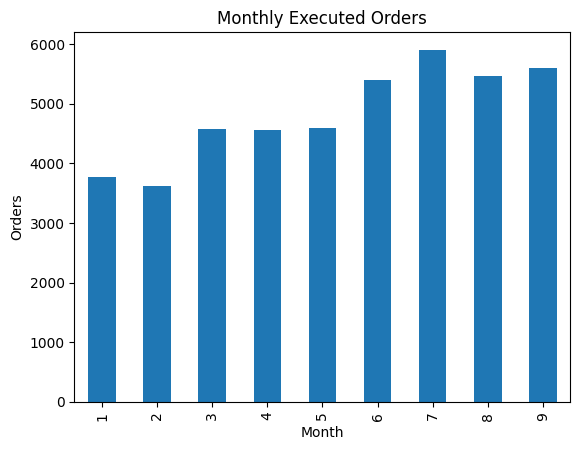

In [31]:
import matplotlib.pyplot as plt

# Monthly trading orders
monthly_orders["total_orders"].plot(
    kind="bar",
    title="Monthly Executed Orders"
)
plt.xlabel("Month")
plt.ylabel("Orders")
plt.show()

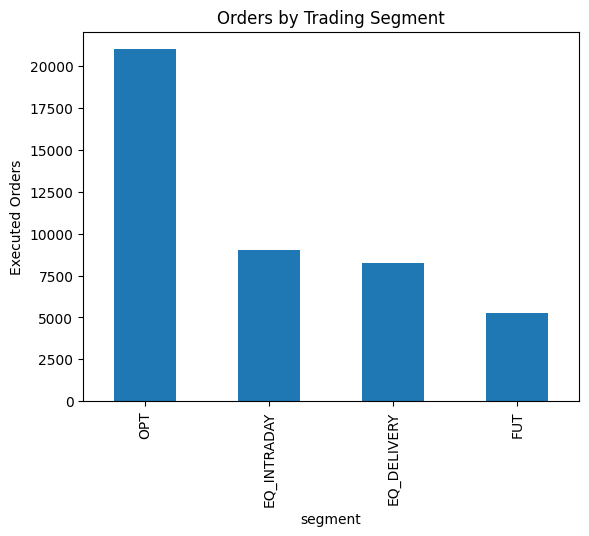

In [32]:
# Segment distribution
segment_analysis["total_orders"].plot(
    kind="bar",
    title="Orders by Trading Segment"
)
plt.ylabel("Executed Orders")
plt.show()

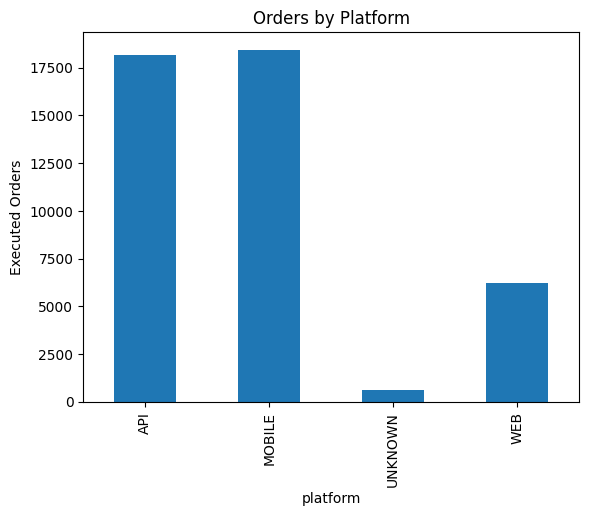

In [33]:
# Platform distribution
platform_analysis["total_orders"].plot(
    kind="bar",
    title="Orders by Platform"
)
plt.ylabel("Executed Orders")
plt.show()

```markdown
## 5. Feature Engineering for Churn Prediction
To train our model, we establish a robust point-in-time snapshot. We group historical orders before August 31, 2026, to engineer predictive features like trading frequency, turnover, active trading days, recency, and client demographics.
```

In [34]:
as_of_date = pd.Timestamp("2026-08-31")

# Use only January-August orders
orders_before_sep = orders_clean[
    (orders_clean["order_ts"] <= "2026-08-31 23:59:59") &
    (orders_clean["status"] == "EXECUTED")
].copy()

print("Orders available for features:", len(orders_before_sep))

Orders available for features: 37890


In [35]:
recent_clients = orders_before_sep[
    orders_before_sep["order_ts"].dt.month.isin([7, 8])
]["client_id"].unique()

print("Eligible clients:", len(recent_clients))

Eligible clients: 1684


In [36]:
client_features = orders_before_sep.groupby("client_id").agg(
    total_orders=("order_id", "count"),
    total_turnover=("turnover_inr", lambda x: x[x >= 0].sum()),
    active_days=("order_ts", lambda x: x.dt.date.nunique()),
    last_trade=("order_ts", "max")
).reset_index()

client_features["days_since_last_trade"] = (
    as_of_date - client_features["last_trade"].dt.normalize()
).dt.days

print(client_features.head())

  client_id  total_orders  total_turnover  active_days          last_trade  \
0  TJ100000             1         6623.17            1 2026-06-22 14:35:17   
1  TJ100001             3       157388.40            3 2026-04-07 13:35:04   
2  TJ100002             1         9930.56            1 2026-07-15 11:30:30   
3  TJ100003             4       956204.13            4 2026-08-17 11:15:17   
4  TJ100004             8       363302.63            8 2026-04-28 11:23:20   

   days_since_last_trade  
0                     70  
1                    146  
2                     47  
3                     14  
4                    125  


In [37]:
last_30 = orders_before_sep[
    orders_before_sep["order_ts"] >= "2026-08-02"
]

previous_30 = orders_before_sep[
    (orders_before_sep["order_ts"] >= "2026-07-03") &
    (orders_before_sep["order_ts"] < "2026-08-02")
]

recent_activity = last_30.groupby("client_id").size()

previous_activity = previous_30.groupby("client_id").size()

client_features["orders_last_30d"] = (
    client_features["client_id"].map(recent_activity).fillna(0)
)

client_features["orders_previous_30d"] = (
    client_features["client_id"].map(previous_activity).fillna(0)
)

print(client_features.head())

  client_id  total_orders  total_turnover  active_days          last_trade  \
0  TJ100000             1         6623.17            1 2026-06-22 14:35:17   
1  TJ100001             3       157388.40            3 2026-04-07 13:35:04   
2  TJ100002             1         9930.56            1 2026-07-15 11:30:30   
3  TJ100003             4       956204.13            4 2026-08-17 11:15:17   
4  TJ100004             8       363302.63            8 2026-04-28 11:23:20   

   days_since_last_trade  orders_last_30d  orders_previous_30d  
0                     70              0.0                  0.0  
1                    146              0.0                  0.0  
2                     47              0.0                  1.0  
3                     14              1.0                  0.0  
4                    125              0.0                  0.0  


In [38]:
client_features = client_features.merge(
    clients_clean.drop(columns=["last_login_date"]),
    on="client_id",
    how="left"
)

client_features["onboarding_date"] = pd.to_datetime(
    client_features["onboarding_date"]
)

client_features["account_age_days"] = (
    as_of_date - client_features["onboarding_date"]
).dt.days

print(client_features.head())

  client_id  total_orders  total_turnover  active_days          last_trade  \
0  TJ100000             1         6623.17            1 2026-06-22 14:35:17   
1  TJ100001             3       157388.40            3 2026-04-07 13:35:04   
2  TJ100002             1         9930.56            1 2026-07-15 11:30:30   
3  TJ100003             4       956204.13            4 2026-08-17 11:15:17   
4  TJ100004             8       363302.63            8 2026-04-28 11:23:20   

   days_since_last_trade  orders_last_30d  orders_previous_30d  \
0                     70              0.0                  0.0   
1                    146              0.0                  0.0   
2                     47              0.0                  1.0   
3                     14              1.0                  0.0   
4                    125              0.0                  0.0   

  onboarding_date city_tier age_band acquisition_channel  fno_enabled  \
0      2026-06-17    TIER 1    26-35            PAID_ADS     

In [39]:
september_active = orders_clean[
    (orders_clean["order_ts"].dt.month == 9) &
    (orders_clean["status"] == "EXECUTED")
]["client_id"].unique()

client_features = client_features[
    client_features["client_id"].isin(recent_clients)
].copy()

client_features["churn"] = (
    ~client_features["client_id"].isin(september_active)
).astype(int)

print(client_features["churn"].value_counts())

churn
0    1004
1     680
Name: count, dtype: int64


In [40]:
print("Final dataset shape:", client_features.shape)

print("\nChurn distribution:")
print(client_features["churn"].value_counts(normalize=True) * 100)

print("\nFinal columns:")
print(client_features.columns.tolist())

Final dataset shape: (1684, 16)

Churn distribution:
churn
0    59.619952
1    40.380048
Name: proportion, dtype: float64

Final columns:
['client_id', 'total_orders', 'total_turnover', 'active_days', 'last_trade', 'days_since_last_trade', 'orders_last_30d', 'orders_previous_30d', 'onboarding_date', 'city_tier', 'age_band', 'acquisition_channel', 'fno_enabled', 'api_enabled', 'account_age_days', 'churn']


In [41]:
client_features.to_csv("client_features.csv", index=False)

In [42]:
print("Minimum last trade:",
      client_features["last_trade"].min())

print("Maximum last trade:",
      client_features["last_trade"].max())

print("\nClients with last trade before July:")
print(
    client_features[
        client_features["last_trade"] < "2026-07-01"
    ][["client_id", "last_trade"]].head(10)
)

Minimum last trade: 2026-07-01 10:07:43
Maximum last trade: 2026-08-31 15:29:51

Clients with last trade before July:
Empty DataFrame
Columns: [client_id, last_trade]
Index: []


In [43]:
check = orders_before_sep[
    orders_before_sep["order_ts"].dt.month.isin([7, 8])
]

print("Unique July-August clients:", check["client_id"].nunique())

print("Clients in feature dataset:", client_features["client_id"].nunique())

print("Eligible clients missing from feature dataset:",
      len(set(check["client_id"]) - set(client_features["client_id"])))

Unique July-August clients: 1684
Clients in feature dataset: 1684
Eligible clients missing from feature dataset: 0


In [44]:
def create_monthly_dataset(orders, clients, prediction_date):

    date = pd.Timestamp(prediction_date)

    # Current month + previous complete calendar month
    start_date = (
        date.to_period("M") - 1
    ).start_time

    past = orders[
        (orders["order_ts"] <= date + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)) &
        (orders["status"] == "EXECUTED")
    ].copy()

    recent = past[
        past["order_ts"] >= start_date
    ]

    eligible = recent["client_id"].unique()

    features = past[
        past["client_id"].isin(eligible)
    ].groupby("client_id").agg(
        total_orders=("order_id", "count"),
        total_turnover=("turnover_inr", lambda x: x[x >= 0].sum()),
        active_days=("order_ts", lambda x: x.dt.date.nunique()),
        last_trade=("order_ts", "max")
    ).reset_index()

    features["days_since_last_trade"] = (
        date - features["last_trade"].dt.normalize()
    ).dt.days

    features["recent_orders"] = (
        features["client_id"]
        .map(recent.groupby("client_id").size())
        .fillna(0)
    )

    features = features.merge(
        clients.drop(columns=["last_login_date"]),
        on="client_id",
        how="left"
    )

    features["account_age_days"] = (
        date - features["onboarding_date"]
    ).dt.days

    # Following calendar month for churn label
    next_month_start = (
        date.to_period("M") + 1
    ).start_time

    next_month_end = (
        date.to_period("M") + 2
    ).start_time

    future = orders[
        (orders["order_ts"] >= next_month_start) &
        (orders["order_ts"] < next_month_end) &
        (orders["status"] == "EXECUTED")
    ]

    active_next = future["client_id"].unique()

    features["churn"] = (
        ~features["client_id"].isin(active_next)
    ).astype(int)

    return features

```markdown
## 6. Model Training & Validation Strategy
To avoid data leakage, we build monthly point-in-time datasets (April, May, June, July) to train and evaluate our predictive models. This matches how the system would behave in a production environment.
```

In [45]:
april_data = create_monthly_dataset(orders_clean, clients_clean, "2026-04-30")
may_data = create_monthly_dataset(orders_clean, clients_clean, "2026-05-31")
june_data = create_monthly_dataset(orders_clean, clients_clean, "2026-06-30")
july_data = create_monthly_dataset(orders_clean, clients_clean, "2026-07-31")

train_data = pd.concat(
    [april_data, may_data, june_data],
    ignore_index=True
)

print("April:", april_data.shape)
print("May:", may_data.shape)
print("June:", june_data.shape)
print("July:", july_data.shape)
print("Training:", train_data.shape)

print("\nJuly churn distribution:")
print(july_data["churn"].value_counts())

print("\nJuly last trade date range:")
print(july_data["last_trade"].min())
print(july_data["last_trade"].max())

April: (1511, 15)
May: (1523, 15)
June: (1566, 15)
July: (1665, 15)
Training: (4600, 15)

July churn distribution:
churn
0    1002
1     663
Name: count, dtype: int64

July last trade date range:
2026-06-01 09:24:20
2026-07-31 15:29:57


In [46]:
baseline = july_data.sort_values(
    "days_since_last_trade",
    ascending=False
)

baseline_top200 = baseline.head(200)

actual_churners = baseline_top200["churn"].sum()
precision = actual_churners / 200
overall_churn = july_data["churn"].mean()
lift = precision / overall_churn

print("Updated Baseline Results")
print("------------------------")
print("Selected clients:", 200)
print("Actual churners:", actual_churners)
print("Precision@200:", round(precision, 4))
print("Overall churn rate:", round(overall_churn, 4))
print("Lift@200:", round(lift, 4))

Updated Baseline Results
------------------------
Selected clients: 200
Actual churners: 144
Precision@200: 0.72
Overall churn rate: 0.3982
Lift@200: 1.8081


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Features used by the model
numeric_features = [
    "total_orders",
    "total_turnover",
    "active_days",
    "days_since_last_trade",
    "account_age_days"
]

categorical_features = [
    "city_tier",
    "age_band",
    "acquisition_channel",
    "fno_enabled",
    "api_enabled"
]

feature_columns = numeric_features + categorical_features

# Training and validation data
X_train = train_data[feature_columns]
y_train = train_data["churn"]

X_val = july_data[feature_columns]
y_val = july_data["churn"]

# Preprocessing numerical and categorical columns
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Logistic Regression model
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict churn probabilities
val_probabilities = logistic_model.predict_proba(X_val)[:, 1]

# Evaluate model
roc_auc = roc_auc_score(y_val, val_probabilities)
pr_auc = average_precision_score(y_val, val_probabilities)

# Select top 200 high-risk clients
logistic_results = july_data[["client_id", "churn"]].copy()
logistic_results["risk_score"] = val_probabilities

logistic_top200 = logistic_results.sort_values(
    "risk_score",
    ascending=False
).head(200)

actual_churners = logistic_top200["churn"].sum()
precision_200 = actual_churners / 200
lift_200 = precision_200 / y_val.mean()

print("Logistic Regression Results")
print("---------------------------")
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("Actual churners in top 200:", actual_churners)
print("Precision@200:", round(precision_200, 4))
print("Lift@200:", round(lift_200, 4))

Logistic Regression Results
---------------------------
ROC-AUC: 0.7826
PR-AUC: 0.6586
Actual churners in top 200: 141
Precision@200: 0.705
Lift@200: 1.7705


```markdown
### Machine Learning - Random Forest Classifier
Next, we train a Random Forest ensemble model to capture non-linear relationships and interactions among features.
```

In [48]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predict probabilities
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Evaluate
rf_roc_auc = roc_auc_score(y_val, rf_probabilities)
rf_pr_auc = average_precision_score(y_val, rf_probabilities)

# Select top 200
rf_results = july_data[["client_id", "churn"]].copy()
rf_results["risk_score"] = rf_probabilities

rf_top200 = rf_results.sort_values(
    "risk_score",
    ascending=False
).head(200)

rf_churners = rf_top200["churn"].sum()
rf_precision = rf_churners / 200
rf_lift = rf_precision / y_val.mean()

print("Random Forest Results")
print("---------------------")
print("ROC-AUC:", round(rf_roc_auc, 4))
print("PR-AUC:", round(rf_pr_auc, 4))
print("Actual churners in top 200:", rf_churners)
print("Precision@200:", round(rf_precision, 4))
print("Lift@200:", round(rf_lift, 4))

Random Forest Results
---------------------
ROC-AUC: 0.7978
PR-AUC: 0.6718
Actual churners in top 200: 145
Precision@200: 0.725
Lift@200: 1.8207


In [49]:
# Get feature names after preprocessing
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest feature importance
importances = rf_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# Map encoded categorical columns back to their original feature
def get_original_feature(name):
    name = name.replace("num__", "").replace("cat__", "")

    for col in categorical_features:
        if name.startswith(col + "_"):
            return col

    return name

importance_df["original_feature"] = (
    importance_df["feature"].apply(get_original_feature)
)

# Combine importance of one-hot encoded categories
grouped_importance = (
    importance_df.groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Feature Importance")
print(grouped_importance)

Feature Importance
        original_feature  importance
0  days_since_last_trade    0.180912
1            active_days    0.172837
2           total_orders    0.166396
3         total_turnover    0.158640
4       account_age_days    0.121068
5            api_enabled    0.054512
6    acquisition_channel    0.046126
7               age_band    0.044679
8              city_tier    0.033136
9            fno_enabled    0.021694


```markdown
### Model Interpretability
Let's check the global feature importances of our Random Forest model to understand what factors drive customer churn risk the most.
```

In [50]:
# Combine all historical snapshots for final training
final_train_data = pd.concat(
    [april_data, may_data, june_data, july_data],
    ignore_index=True
)

X_final_train = final_train_data[feature_columns]
y_final_train = final_train_data["churn"]

# Create and train the final Random Forest model
final_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

final_rf_model.fit(X_final_train, y_final_train)

# Score eligible clients as of August 31
X_september = client_features[feature_columns]

september_probabilities = final_rf_model.predict_proba(
    X_september
)[:, 1]

# Create the ranked client list
final_scores = client_features[["client_id"]].copy()
final_scores["risk_score"] = september_probabilities

final_top200 = final_scores.sort_values(
    "risk_score",
    ascending=False
).head(200).reset_index(drop=True)

final_top200["rank"] = final_top200.index + 1

print("Final Model Summary")
print("-------------------")
print("Historical training rows:", len(final_train_data))
print("Eligible August clients:", len(client_features))
print("Selected clients:", len(final_top200))

print("\nTop 10 high-risk clients:")
print(final_top200.head(10))

print("\nRisk score summary:")
print(final_top200["risk_score"].describe())

Final Model Summary
-------------------
Historical training rows: 6265
Eligible August clients: 1684
Selected clients: 200

Top 10 high-risk clients:
  client_id  risk_score  rank
0  TJ101100    0.898899     1
1  TJ103526    0.893531     2
2  TJ102308    0.887199     3
3  TJ100959    0.884969     4
4  TJ103751    0.882948     5
5  TJ102880    0.881671     6
6  TJ103982    0.878550     7
7  TJ100326    0.875185     8
8  TJ103583    0.871194     9
9  TJ102857    0.870968    10

Risk score summary:
count    200.000000
mean       0.795905
std        0.036810
min        0.746179
25%        0.764807
50%        0.788151
75%        0.819778
max        0.898899
Name: risk_score, dtype: float64


```markdown
## 7. Operational calling list with Actionable Playbooks
Using our model's predictions as of August 31, we segment high-risk accounts and assign tailored, rule-based outreach actions to help customer relationship agents intervene effectively.
```

In [51]:
# Keep only information available on August 31
call_list = final_top200.merge(
    client_features[
        [
            "client_id",
            "days_since_last_trade",
            "orders_last_30d",
            "orders_previous_30d",
            "total_orders",
            "total_turnover",
            "city_tier",
            "acquisition_channel"
        ]
    ],
    on="client_id",
    how="left"
)

# Assign simple, explainable call recommendations
conditions = [
    call_list["days_since_last_trade"] >= 30,
    call_list["orders_last_30d"] < call_list["orders_previous_30d"]
]

actions = [
    "Reactivation call - prolonged inactivity",
    "Engagement call - declining trading activity"
]

call_list["suggested_action"] = np.select(
    conditions,
    actions,
    default="Relationship call - understand trading needs"
)

print("Top 200 Calling List")
print("--------------------")
print(call_list.head(10).to_string(index=False))

print("\nSuggested Action Distribution:")
print(call_list["suggested_action"].value_counts())

Top 200 Calling List
--------------------
client_id  risk_score  rank  days_since_last_trade  orders_last_30d  orders_previous_30d  total_orders  total_turnover city_tier acquisition_channel                         suggested_action
 TJ101100    0.898899     1                     34              0.0                  1.0             1         6139.71    TIER 1            REFERRAL Reactivation call - prolonged inactivity
 TJ103526    0.893531     2                     45              0.0                  1.0             2       148002.88    TIER 1            PAID_ADS Reactivation call - prolonged inactivity
 TJ102308    0.887199     3                     47              0.0                  1.0             1        29376.85    TIER 2            PAID_ADS Reactivation call - prolonged inactivity
 TJ100959    0.884969     4                     56              0.0                  1.0             1        59984.24    TIER 1            PAID_ADS Reactivation call - prolonged inactivity
 TJ10375

In [52]:
# Retrieve actual September outcomes for eligible clients
actual_outcomes = client_features[
    ["client_id", "churn"]
].copy()

# Evaluate Random Forest top 200
rf_evaluation = call_list.merge(
    actual_outcomes,
    on="client_id",
    how="left"
)

rf_actual_churners = rf_evaluation["churn"].sum()
rf_precision = rf_actual_churners / 200

total_actual_churners = actual_outcomes["churn"].sum()
rf_recall = rf_actual_churners / total_actual_churners

overall_churn_rate = actual_outcomes["churn"].mean()
rf_lift = rf_precision / overall_churn_rate

# Evaluate simple inactivity baseline on the same August cohort
final_baseline = client_features.sort_values(
    "days_since_last_trade",
    ascending=False
).head(200)

baseline_churners = final_baseline["churn"].sum()
baseline_precision = baseline_churners / 200
baseline_lift = baseline_precision / overall_churn_rate

print("September Evaluation")
print("--------------------")
print("Total eligible clients:", len(actual_outcomes))
print("Total actual churners:", total_actual_churners)
print("Overall churn rate:", round(overall_churn_rate, 4))

print("\nRandom Forest:")
print("Actual churners in top 200:", rf_actual_churners)
print("Precision@200:", round(rf_precision, 4))
print("Recall@200:", round(rf_recall, 4))
print("Lift@200:", round(rf_lift, 4))

print("\nInactivity Baseline:")
print("Actual churners in top 200:", baseline_churners)
print("Precision@200:", round(baseline_precision, 4))
print("Lift@200:", round(baseline_lift, 4))

September Evaluation
--------------------
Total eligible clients: 1684
Total actual churners: 680
Overall churn rate: 0.4038

Random Forest:
Actual churners in top 200: 147
Precision@200: 0.735
Recall@200: 0.2162
Lift@200: 1.8202

Inactivity Baseline:
Actual churners in top 200: 137
Precision@200: 0.685
Lift@200: 1.6964


In [53]:
# Executed orders during July and August
recent_brokerage = orders_clean[
    (orders_clean["order_ts"] >= "2026-07-01") &
    (orders_clean["order_ts"] < "2026-09-01") &
    (orders_clean["status"] == "EXECUTED")
].copy()

# Calculate brokerage generated by each client
brokerage_by_client = (
    recent_brokerage.groupby("client_id")["validated_brokerage"]
    .sum()
    .reset_index(name="brokerage_2_months")
)

# Average monthly brokerage across the two-month period
brokerage_by_client["avg_monthly_brokerage"] = (
    brokerage_by_client["brokerage_2_months"] / 2
)

# Attach brokerage to the top-200 calling list
call_list = call_list.merge(
    brokerage_by_client[
        ["client_id", "avg_monthly_brokerage"]
    ],
    on="client_id",
    how="left"
)

call_list["avg_monthly_brokerage"] = (
    call_list["avg_monthly_brokerage"].fillna(0)
)

# Estimate brokerage at risk
total_brokerage_at_risk = (
    call_list["avg_monthly_brokerage"].sum()
)

# Illustrative probability-weighted estimate
probability_weighted_brokerage = (
    call_list["avg_monthly_brokerage"] *
    call_list["risk_score"]
).sum()

print("Brokerage Impact")
print("----------------")
print(
    "Average monthly brokerage of top 200:",
    round(total_brokerage_at_risk, 2)
)
print(
    "Risk-score-weighted brokerage estimate:",
    round(probability_weighted_brokerage, 2)
)

print("\nTop 10 clients with brokerage:")
print(
    call_list[
        [
            "client_id",
            "risk_score",
            "avg_monthly_brokerage",
            "suggested_action"
        ]
    ].head(10).to_string(index=False)
)

Brokerage Impact
----------------
Average monthly brokerage of top 200: 1501.57
Risk-score-weighted brokerage estimate: 1196.45

Top 10 clients with brokerage:
client_id  risk_score  avg_monthly_brokerage                         suggested_action
 TJ101100    0.898899               1.534928 Reactivation call - prolonged inactivity
 TJ103526    0.893531              10.000000 Reactivation call - prolonged inactivity
 TJ102308    0.887199               7.344212 Reactivation call - prolonged inactivity
 TJ100959    0.884969              10.000000 Reactivation call - prolonged inactivity
 TJ103751    0.882948               1.605088 Reactivation call - prolonged inactivity
 TJ102880    0.881671              10.000000 Reactivation call - prolonged inactivity
 TJ103982    0.878550               4.058655 Reactivation call - prolonged inactivity
 TJ100326    0.875185              10.000000 Reactivation call - prolonged inactivity
 TJ103583    0.871194              10.000000 Reactivation call - p

In [54]:
# Final columns for submission
final_columns = [
    "rank",
    "client_id",
    "risk_score",
    "days_since_last_trade",
    "orders_last_30d",
    "orders_previous_30d",
    "total_orders",
    "total_turnover",
    "city_tier",
    "acquisition_channel",
    "avg_monthly_brokerage",
    "suggested_action"
]

top200_export = call_list[final_columns].copy()

# Save CSV
top200_export.to_csv("top200.csv", index=False)

print("File created: top200.csv")
print("Rows:", len(top200_export))
print("Columns:", len(top200_export.columns))
print("\nPreview:")
print(top200_export.head())

File created: top200.csv
Rows: 200
Columns: 12

Preview:
   rank client_id  risk_score  days_since_last_trade  orders_last_30d  \
0     1  TJ101100    0.898899                     34              0.0   
1     2  TJ103526    0.893531                     45              0.0   
2     3  TJ102308    0.887199                     47              0.0   
3     4  TJ100959    0.884969                     56              0.0   
4     5  TJ103751    0.882948                     45              0.0   

   orders_previous_30d  total_orders  total_turnover city_tier  \
0                  1.0             1         6139.71    TIER 1   
1                  1.0             2       148002.88    TIER 1   
2                  1.0             1        29376.85    TIER 2   
3                  1.0             1        59984.24    TIER 1   
4                  1.0             1         6420.35    TIER 2   

  acquisition_channel  avg_monthly_brokerage  \
0            REFERRAL               1.534928   
1          

```markdown
## 8. Financial Impact & Out-of-Sample Performance Evaluation
Finally, we evaluate how our model performed during September 2026. We look at classification metrics (precision, recall, lift) against our baseline, and measure the historical brokerage revenue currently at risk.
```

In [55]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "Eligible clients",
        "Actual churners",
        "Overall churn rate",
        "Random Forest top-200 churners",
        "Random Forest Precision@200",
        "Random Forest Recall@200",
        "Random Forest Lift@200",
        "Baseline top-200 churners",
        "Baseline Precision@200",
        "Baseline Lift@200",
        "Historical monthly brokerage at risk",
        "Risk-weighted brokerage estimate"
    ],
    "Value": [
        len(actual_outcomes),
        total_actual_churners,
        overall_churn_rate,
        rf_actual_churners,
        rf_precision,
        rf_recall,
        rf_lift,
        baseline_churners,
        baseline_precision,
        baseline_lift,
        total_brokerage_at_risk,
        probability_weighted_brokerage
    ]
})

print(evaluation_summary.to_string(index=False))

                              Metric       Value
                    Eligible clients 1684.000000
                     Actual churners  680.000000
                  Overall churn rate    0.403800
      Random Forest top-200 churners  147.000000
         Random Forest Precision@200    0.735000
            Random Forest Recall@200    0.216176
              Random Forest Lift@200    1.820206
           Baseline top-200 churners  137.000000
              Baseline Precision@200    0.685000
                   Baseline Lift@200    1.696382
Historical monthly brokerage at risk 1501.570380
    Risk-weighted brokerage estimate 1196.453713
